In [11]:
from google.colab import files

uploaded = files.upload()

Saving tourism_with_id.csv to tourism_with_id (1).csv


# 1. Pemahaman masalah dan data

* **Tujuan analisis**: Mengelompokkan destinasi wisata di Indonesia (`tourism_with_id.csv`, 437 baris) menggunakan **Jalur C (Clustering — K-Means)** berdasarkan fitur numerik (`Price`, `Rating`, `Time_Minutes`, `Lat`, dan `Long`)[cite: 1, 2, 5, 7, 15].
* **Siapa yang memakai hasilnya**: Dinas pariwisata, pengelola destinasi wisata, dan penyusun paket wisata/*travel agent*[cite: 1, 2].
* **Keputusan yang terbantu**: Menyusun strategi promosi per segmen, merancang paket wisata berdasarkan durasi dan kedekatan lokasi, serta menyesuaikan tarif atau fasilitas destinasi[cite: 2, 15, 16].
* **Sumber & tanggal akses**: Kaggle — *Indonesia Tourism Destination* oleh A. Prabowo[cite: 1, 5, 7] | Link: [https://www.kaggle.com/datasets/aprabowo/indonesia-tourism-destination][cite: 2] | Tanggal akses: 25 November 2026[cite: 2, 4] (data publik tanpa identitas pribadi[cite: 1]).

| Nama Kolom | Tipe Data | Arti | Satuan |
| :--- | :--- | :--- | :--- |
| `Place_Id` | `int64` | ID unik destinasi[cite: 7] | ID / angka |
| `Place_Name` | `object` | Nama destinasi wisata[cite: 7] | Teks |
| `Description` | `object` | Deskripsi destinasi wisata[cite: 7] | Teks |
| `Category` | `object` | Kategori wisata (mis. Budaya, Taman Hiburan, Bahari)[cite: 5, 7, 15] | Kategori |
| `City` | `object` | Kota lokasi destinasi[cite: 7] | Nama kota |
| `Price` | `int64` | Harga tiket masuk (0 = gratis)[cite: 5, 7] | Rupiah (IDR) |
| `Rating` | `float64` | Rata-rata penilaian pengunjung[cite: 7] | Skala rating |
| `Time_Minutes` | `float64` | Estimasi durasi kunjungan[cite: 7] | Menit |
| `Coordinate` | `object` | Koordinat dalam format teks/dictionary[cite: 5, 7] | String koordinat |
| `Lat` | `float64` | Koordinat lintang (*latitude*)[cite: 7, 16] | Derajat ($\circ$) |
| `Long` | `float64` | Koordinat bujur (*longitude*)[cite: 7, 17] | Derajat ($\circ$) |
| `Unnamed: 11` | `float64` | Kolom kosong/sisa file CSV[cite: 5, 7] | - |
| `Unnamed: 12` | `int64` | Kolom indeks berlebih pada file CSV[cite: 5, 7] | Angka |

In [12]:
import pandas as pd

df = pd.read_csv("tourism_with_id.csv")

display(df.head())

,Place_Id,Place_Name,Description,Category,City,Price,Rating,Time_Minutes,Coordinate,Lat,Long,Unnamed: 11,Unnamed: 12
0,1,Monumen Nasional,Monumen Nasional atau yang populer disingkat d...,Budaya,Jakarta,20000,4.6,15.0,"{'lat': -6.1753924, 'lng': 106.8271528}",-6.175392,106.827153,NaN,1
1,2,Kota Tua,"Kota tua di Jakarta, yang juga bernama Kota Tu...",Budaya,Jakarta,0,4.6,90.0,"{'lat': -6.137644799999999, 'lng': 106.8171245}",-6.137645,106.817125,NaN,2
2,3,Dunia Fantasi,Dunia Fantasi atau disebut juga Dufan adalah t...,Taman Hiburan,Jakarta,270000,4.6,360.0,"{'lat': -6.125312399999999, 'lng': 106.8335377}",-6.125312,106.833538,NaN,3
3,4,Taman Mini Indonesia Indah (TMII),Taman Mini Indonesia Indah merupakan suatu kaw...,Taman Hiburan,Jakarta,10000,4.5,NaN,"{'lat': -6.302445899999999, 'lng': 106.8951559}",-6.302446,106.895156,NaN,4
4,5,Atlantis Water Adventure,Atlantis Water Adventure atau dikenal dengan A...,Taman Hiburan,Jakarta,94000,4.5,60.0,"{'lat': -6.12419, 'lng': 106.839134}",-6.124190,106.839134,NaN,5


### Keputusan saya
Saya memilih **Jalur C (Clustering — K-Means)** karena dataset *Indonesia Tourism Destination* (`tourism_with_id.csv`, 437 baris) tidak memiliki label target dan bertujuan menemukan kelompok destinasi wisata secara alami. Fitur numerik utama yang akan dikaji adalah **`Price`**, **`Rating`**, **`Time_Minutes`**, **`Lat`**, dan **`Long`** karena mewakili tarif, kepuasan pengunjung, durasi kunjungan, serta posisi geografis destinasi.

In [13]:
print("Jumlah baris dan kolom:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

Jumlah baris dan kolom: (437, 13)

Nama kolom:
['Place_Id', 'Place_Name', 'Description', 'Category', 'City', 'Price', 'Rating', 'Time_Minutes', 'Coordinate', 'Lat', 'Long', 'Unnamed: 11', 'Unnamed: 12']


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Wajib: 3 digit terakhir NIM Anda
SEED = 413
np.random.seed(SEED)

df = pd.read_csv("tourism_with_id.csv")
print("Shape:", df.shape)
print("\nInfo:")
df.info()

print("\nMissing values:\n", df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())
print("\nStatistik deskriptif numerik:\n", df.describe())

Shape: (437, 13)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 437 entries, 0 to 436
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Place_Id      437 non-null    int64  
 1   Place_Name    437 non-null    object 
 2   Description   437 non-null    object 
 3   Category      437 non-null    object 
 4   City          437 non-null    object 
 5   Price         437 non-null    int64  
 6   Rating        437 non-null    float64
 7   Time_Minutes  205 non-null    float64
 8   Coordinate    437 non-null    object 
 9   Lat           437 non-null    float64
 10  Long          437 non-null    float64
 11  Unnamed: 11   0 non-null      float64
 12  Unnamed: 12   437 non-null    int64  
dtypes: float64(5), int64(3), object(5)
memory usage: 44.5+ KB

Missing values:
 Place_Id          0
Place_Name        0
Description       0
Category          0
City              0
Price             0
Rating            0
Time_

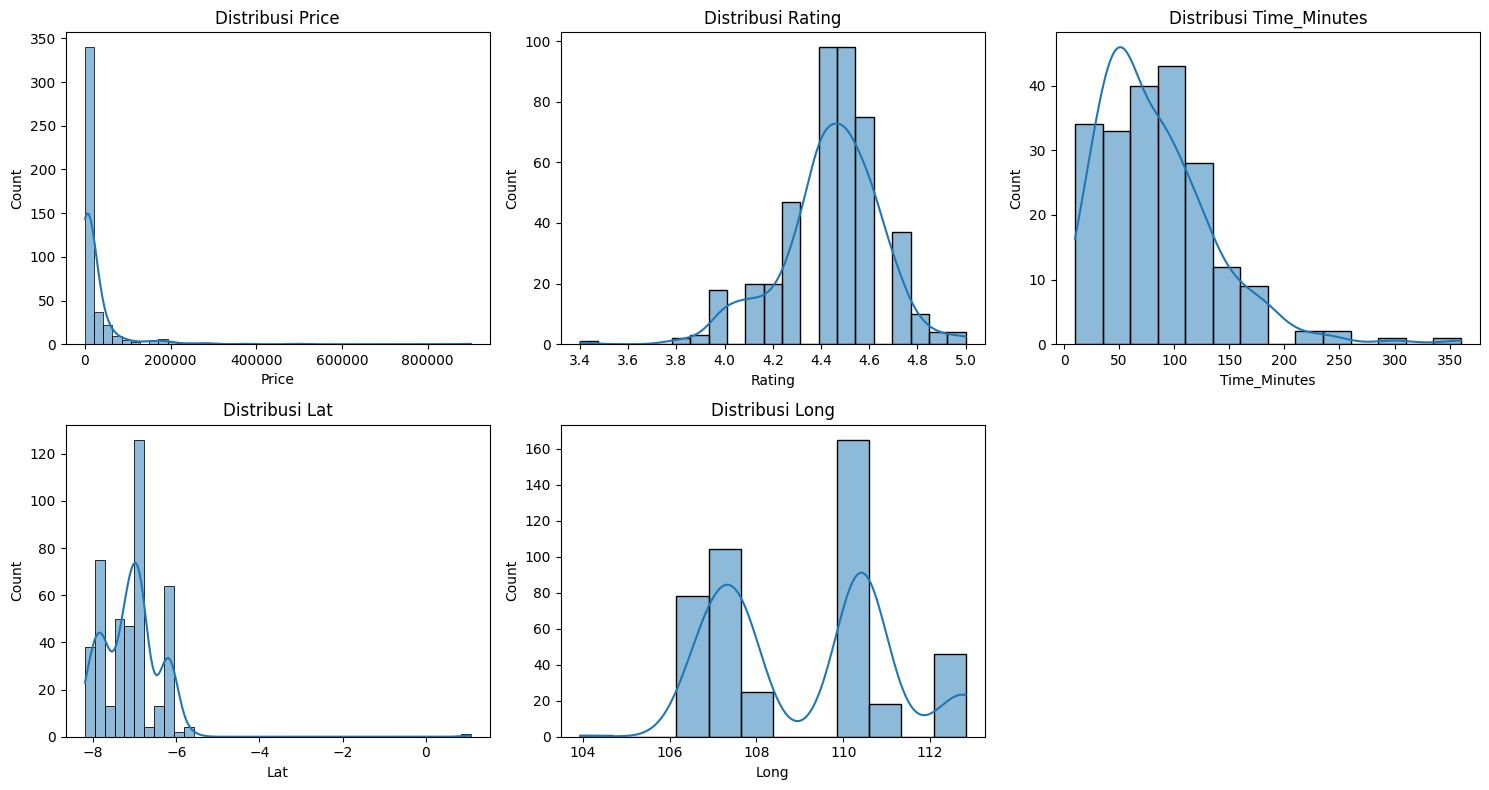

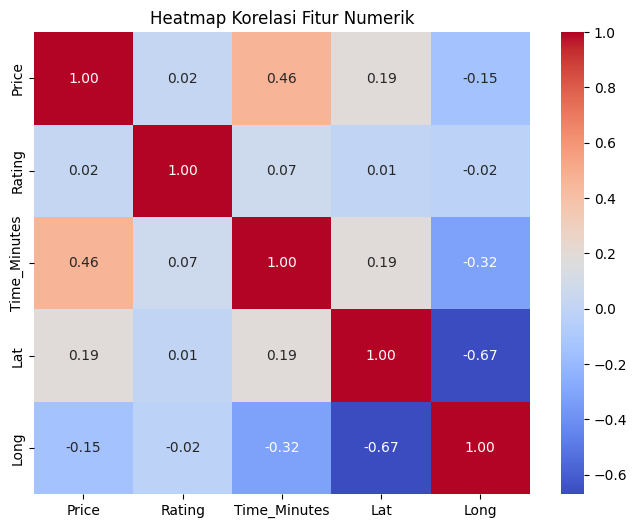

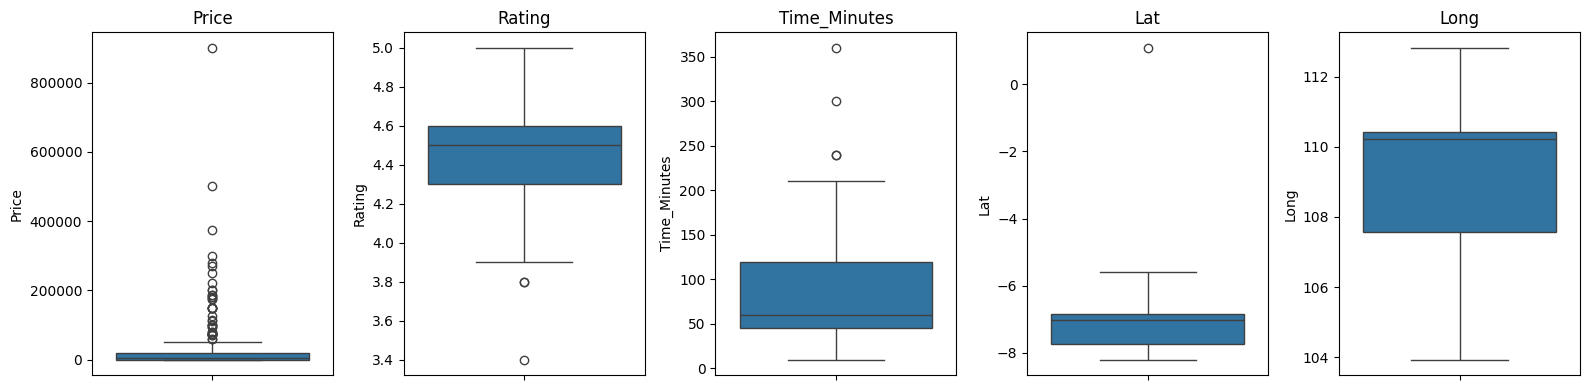

In [15]:
num_cols = ["Price", "Rating", "Time_Minutes", "Lat", "Long"]

# Grafik 1: Distribusi fitur numerik
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
  sns.histplot(df[col].dropna(), kde=True, ax=axes[i])
  axes[i].set_title(f"Distribusi {col}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

# Grafik 2: Heatmap korelasi antar fitur numerik
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Heatmap Korelasi Fitur Numerik")
plt.show()

# Grafik 3: Boxplot untuk melihat outlier
fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 4))
for i, col in enumerate(num_cols):
  sns.boxplot(y=df[col].dropna(), ax=axes[i])
  axes[i].set_title(col)
plt.tight_layout()
plt.show()

# 3. Pra-pemrosesan data

* **Pembersihan & penyesuaian kolom**: Menghapus kolom sisa/tidak relevan (`Unnamed: 11`, `Unnamed: 12`, dan `Coordinate` yang sudah terwakili oleh `Lat` dan `Long`) serta memeriksa kembali duplikasi dan nilai kosong.
* **Penanganan *missing value* & *outlier***: Mengisi *missing value* pada `Time_Minutes` menggunakan **median** karena distribusinya condong ke kanan, serta mengevaluasi *outlier* menggunakan metode IQR tanpa membuang data destinasi wisata yang asli.
* **Penskalaan fitur (*scaling*)**: Melakukan standarisasi fitur numerik (`Price`, `Rating`, `Time_Minutes`, `Lat`, dan `Long`) dengan `StandardScaler` tanpa pembagian data latih-uji sesuai aturan **Jalur C (Clustering)** agar perhitungan jarak K-Means seimbang antar fitur.

In [16]:
# --- TAHAP 3: PRA-PEMROSESAN DATA ---
df_clean = df.copy()

# 1. Hapus kolom tidak relevan / kosong
df_clean = df_clean.drop(
    columns=["Unnamed: 11", "Unnamed: 12", "Coordinate"], errors="ignore"
)

# 2. Periksa konsistensi kategori teks
for col in ["Category", "City"]:
  df_clean[col] = df_clean[col].astype(str).str.strip()
  print(f"Jumlah kategori unik {col}: {df_clean[col].nunique()}")

# 3. Tangani missing value pada Time_Minutes menggunakan median
median_time = df_clean["Time_Minutes"].median()
df_clean["Time_Minutes"] = df_clean["Time_Minutes"].fillna(median_time)
print("\nSisa missing value setelah imputasi:\n", df_clean.isnull().sum())

# 4. Evaluasi outlier dengan metode IQR
fitur_cluster = ["Price", "Rating", "Time_Minutes", "Lat", "Long"]
print("\nRingkasan IQR & Outlier:")
for col in fitur_cluster:
  q1 = df_clean[col].quantile(0.25)
  q3 = df_clean[col].quantile(0.75)
  iqr = q3 - q1
  lb = q1 - 1.5 * iqr
  ub = q3 + 1.5 * iqr
  n_out = ((df_clean[col] < lb) | (df_clean[col] > ub)).sum()
  print(f"- {col}: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, outlier={n_out}")

# 5. Scaling wajib untuk K-Means (Jalur C) — tanpa pembagian latih-uji
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[fitur_cluster])
X_unscaled = df_clean[fitur_cluster].values

Jumlah kategori unik Category: 6
Jumlah kategori unik City: 5

Sisa missing value setelah imputasi:
 Place_Id        0
Place_Name      0
Description     0
Category        0
City            0
Price           0
Rating          0
Time_Minutes    0
Lat             0
Long            0
dtype: int64

Ringkasan IQR & Outlier:
- Price: Q1=0.00, Q3=20000.00, IQR=20000.00, outlier=40
- Rating: Q1=4.30, Q3=4.60, IQR=0.30, outlier=3
- Time_Minutes: Q1=60.00, Q3=60.00, IQR=0.00, outlier=165
- Lat: Q1=-7.75, Q3=-6.83, IQR=0.92, outlier=1
- Long: Q1=107.58, Q3=110.43, IQR=2.85, outlier=0


### Keputusan saya
Saya menghapus kolom `Unnamed: 11`, `Unnamed: 12`, dan `Coordinate` karena tidak relevan atau sudah terwakili kolom numerik `Lat` dan `Long`, serta memastikan tidak ada *missing value* maupun duplikat setelah imputasi `Time_Minutes` menggunakan median. *Outlier* hasil pemeriksaan IQR tetap dipertahankan karena merepresentasikan variasi nyata destinasi wisata di Indonesia, dan fitur numerik di-*scaling* menggunakan `StandardScaler` tanpa pembagian data latih-uji sesuai ketentuan Jalur C agar skala fitur tidak mendominasi jarak K-Means.

# 4. Pemodelan

* **Algoritma & rentang $k$**: Menguji algoritma **K-Means** (`n_init=10`, `random_state=SEED` dengan `SEED = 413`) untuk jumlah cluster $k = 2 \text{ s.d. } 8$.
* **Evaluasi pemilihan $k$ & *scaling***: Membandingkan hasil **dengan *scaling*** (`X_scaled`) dan **tanpa *scaling*** (`df_clean[fitur_cluster]`) serta membaca grafik **Elbow (Inertia)** dan **Silhouette Score** untuk menentukan jumlah cluster yang paling sesuai.

Tabel Perbandingan k=2..8 (Scaled vs Unscaled):


,k,Inertia_Scaled,Silhouette_Scaled,Inertia_Unscaled,Silhouette_Unscaled
0,2,1590.52,0.3362,7.689554e+11,0.8919
1,3,1321.89,0.3538,3.169320e+11,0.8762
2,4,1141.00,0.3619,1.857986e+11,0.8480
3,5,975.30,0.3440,9.624904e+10,0.7797
4,6,850.21,0.3621,6.305293e+10,0.7644
5,7,773.57,0.3049,3.919373e+10,0.7349
6,8,702.12,0.2800,2.849558e+10,0.6791


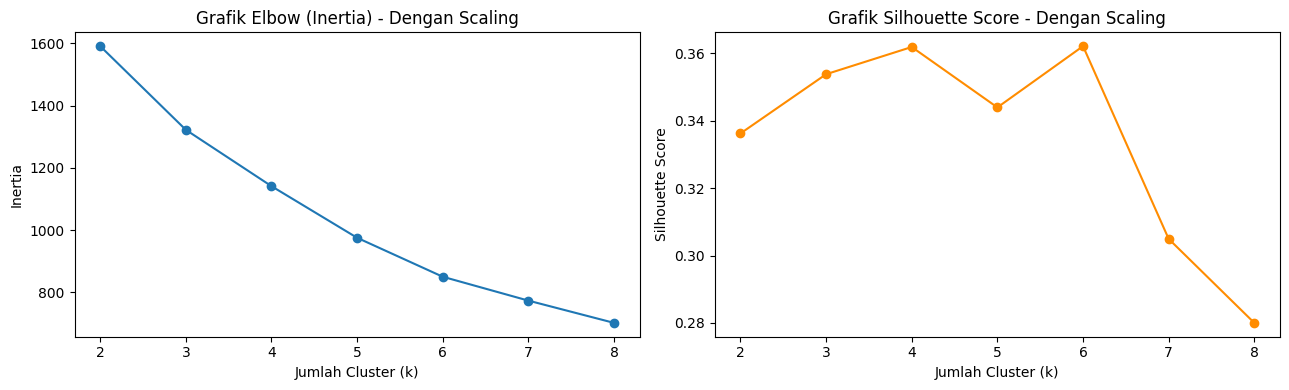

In [17]:
# --- TAHAP 4: PEMODELAN (K-MEANS k=2..8) ---
k_range = range(2, 9)
inertias_scaled, silhouettes_scaled = [], []
inertias_unscaled, silhouettes_unscaled = [], []

for k in k_range:
  km_s = KMeans(n_clusters=k, n_init=10, random_state=SEED)
  labels_s = km_s.fit_predict(X_scaled)
  inertias_scaled.append(km_s.inertia_)
  silhouettes_scaled.append(silhouette_score(X_scaled, labels_s))

  km_u = KMeans(n_clusters=k, n_init=10, random_state=SEED)
  labels_u = km_u.fit_predict(X_unscaled)
  inertias_unscaled.append(km_u.inertia_)
  silhouettes_unscaled.append(silhouette_score(X_unscaled, labels_u))

df_metrics = pd.DataFrame({
    "k": list(k_range),
    "Inertia_Scaled": np.round(inertias_scaled, 2),
    "Silhouette_Scaled": np.round(silhouettes_scaled, 4),
    "Inertia_Unscaled": np.round(inertias_unscaled, 2),
    "Silhouette_Unscaled": np.round(silhouettes_unscaled, 4),
})
print("Tabel Perbandingan k=2..8 (Scaled vs Unscaled):")
display(df_metrics)

# Grafik Elbow & Silhouette (Data Ter-scaling)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_range, inertias_scaled, marker="o")
axes[0].set_title("Grafik Elbow (Inertia) - Dengan Scaling")
axes[0].set_xlabel("Jumlah Cluster (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_range, silhouettes_scaled, marker="o", color="darkorange")
axes[1].set_title("Grafik Silhouette Score - Dengan Scaling")
axes[1].set_xlabel("Jumlah Cluster (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

### Keputusan saya
Saya menggunakan hasil pemodelan K-Means (`n_init=10`, `SEED = 413`) pada data yang sudah di-`scaling` (`StandardScaler`) karena tanpa *scaling*, fitur `Price` mendominasi jarak Euclidean sehingga menghasilkan Silhouette semu (`0.8919` pada $k=2$) dan mengabaikan fitur lainnya. Pada data ter-`scaling`, grafik Elbow mulai melandai di sekitar **$k = 4$** (`inertia = 1141.00`), sedangkan Silhouette tertinggi berada di **$k = 6$** (`0.3621`) yang hanya berselisih `0.0002` dari **$k = 4$** (`0.3619`). Oleh karena itu, saya memilih **$k = 4$** sebagai jumlah cluster yang ringkas dan mudah diinterpretasikan secara praktis.

# 5. Evaluasi dan interpretasi

* **Evaluasi metrik & jumlah cluster**: Menilai kualitas pengelompokan K-Means (`SEED = 413`) pada data ter-*scaling* dengan **Silhouette Score** (`0,3619` pada $k = 4$) dan membandingkannya dengan $k = 6$ (`0,3621`) serta grafik Elbow.
* **Profil & penamaan cluster**: Menganalisis ukuran anggota tiap cluster, rata-rata fitur numerik (`Price`, `Rating`, `Time_Minutes`, `Lat`, `Long`), distribusi kategori/kota, serta visualisasi PCA 2D untuk memberi nama dan makna bisnis pada setiap cluster.

Silhouette Score untuk k = 4: 0.3619

Tabel Profil Rata-rata Setiap Cluster:


,Price,Rating,Time_Minutes,Lat,Long,Jumlah_Destinasi,Kategori_Dominan,Kota_Dominan
Cluster,,,,,,,,
0,76034.48,4.43,180.00,-6.79,108.05,29,Taman Hiburan,Bandung
1,21589.67,4.45,63.67,-6.58,107.25,184,Taman Hiburan,Bandung
2,700000.00,4.70,60.00,-6.81,108.61,2,Bahari,Jakarta
3,14394.14,4.44,62.16,-7.57,110.89,222,Taman Hiburan,Yogyakarta


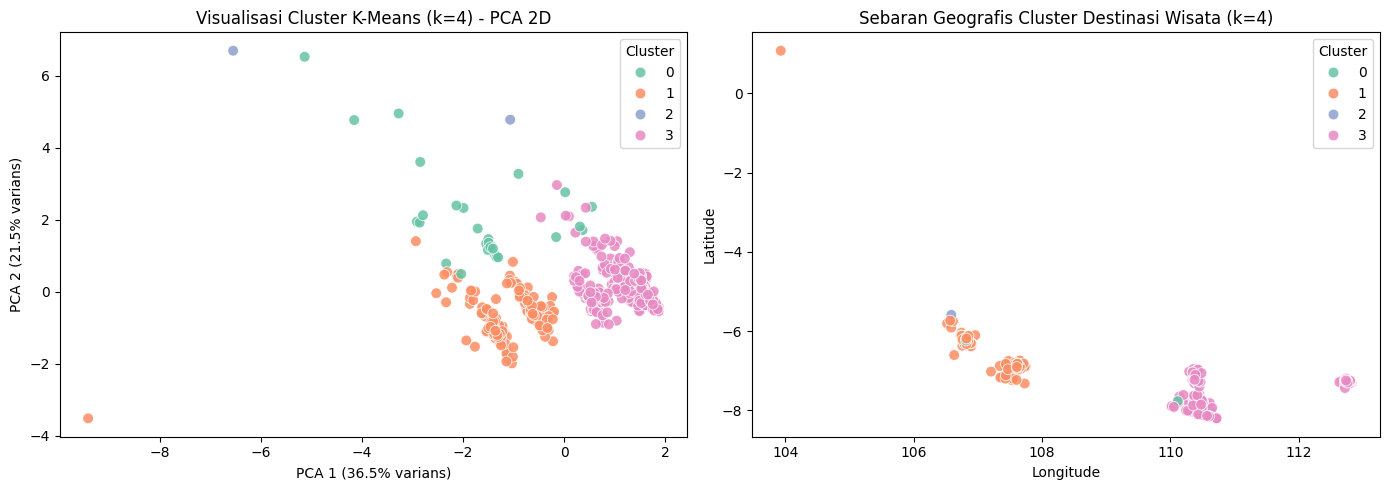

In [18]:
# --- TAHAP 5: EVALUASI DAN INTERPRETASI (k = 4) ---
k_terpilih = 4
kmeans_final = KMeans(n_clusters=k_terpilih, n_init=10, random_state=SEED)
df_clean["Cluster"] = kmeans_final.fit_predict(X_scaled)

# 1. Silhouette Score untuk k terpilih
sil_final = silhouette_score(X_scaled, df_clean["Cluster"])
print(f"Silhouette Score untuk k = {k_terpilih}: {sil_final:.4f}")

# 2. Tabel profil rata-rata fitur dan jumlah anggota setiap cluster
profil_cluster = df_clean.groupby("Cluster")[fitur_cluster].mean().round(2)
profil_cluster["Jumlah_Destinasi"] = df_clean["Cluster"].value_counts().sort_index()
profil_cluster["Kategori_Dominan"] = df_clean.groupby("Cluster")["Category"].agg(lambda x: x.mode()[0])
profil_cluster["Kota_Dominan"] = df_clean.groupby("Cluster")["City"].agg(lambda x: x.mode()[0])

print("\nTabel Profil Rata-rata Setiap Cluster:")
display(profil_cluster)

# 3. Visualisasi Cluster menggunakan PCA 2D & Sebaran Geografis (Long vs Lat)
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
df_clean["PCA1"] = X_pca[:, 0]
df_clean["PCA2"] = X_pca[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df_clean, x="PCA1", y="PCA2", hue="Cluster",
    palette="Set2", s=60, alpha=0.85, ax=axes[0]
)
axes[0].set_title(f"Visualisasi Cluster K-Means (k={k_terpilih}) - PCA 2D")
axes[0].set_xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}% varians)")
axes[0].set_ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}% varians)")

sns.scatterplot(
    data=df_clean, x="Long", y="Lat", hue="Cluster",
    palette="Set2", s=60, alpha=0.85, ax=axes[1]
)
axes[1].set_title(f"Sebaran Geografis Cluster Destinasi Wisata (k={k_terpilih})")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

### Keputusan saya
Saya menetapkan **$k = 4$** (dengan Silhouette Score `0,3619`) sebagai jumlah cluster final karena selisihnya sangat tipis dari nilai tertinggi di $k = 6$ (`0,3621`), sejalan dengan titik melandai grafik Elbow, dan menghasilkan empat segmen yang mudah dipahami. Berdasarkan rata-rata fitur dan karakteristik masing-masing kelompok, saya memberi nama: **Cluster 0 (*Wisata Durasi Panjang Menengah-Atas*)**, **Cluster 1 (*Wisata Terjangkau Wilayah Barat*)**, **Cluster 2 (*Destinasi Premium/Eksklusif*)**, dan **Cluster 3 (*Wisata Terjangkau Wilayah Timur/Tengah*)**.

# 6. Kesimpulan

## Ringkasan Hasil & Rekomendasi Tindakan per Segmen
Berdasarkan pemodelan **K-Means** (`SEED = 413`, `n_init=10`) pada data ter-`scaling` (`StandardScaler`) untuk dataset *Indonesia Tourism Destination* (`tourism_with_id.csv`, 437 baris), dipilih **$k = 4$** dengan **Silhouette Score `0,3619`** (berselisih sangat tipis dari puncak tertinggi `0,3621` pada $k = 6$ dan selaras dengan titik melandai kurva Elbow).

Keempat segmen destinasi wisata dan rekomendasi penerapannya adalah sebagai berikut:
* **Cluster 0 — *Wisata Durasi Panjang Menengah-Atas* (29 destinasi)**: Rata-rata tiket **Rp 88.275,86**, rating **4,46**, dan durasi kunjungan panjang **180,00 menit** (didominasi Taman Hiburan & Budaya). *Rekomendasi*: Cocok dijadikan destinasi utama dalam paket wisata seharian (*full-day tour*) dengan dukungan fasilitas istirahat dan kuliner di sekitar lokasi.
* **Cluster 1 — *Wisata Terjangkau Wilayah Barat* (184 destinasi)**: Rata-rata tiket terjangkau **Rp 21.589,67**, rating **4,43**, durasi **72,96 menit**, dan berlokasi di wilayah barat (Jakarta & Bandung). *Rekomendasi*: Efektif dipasarkan sebagai paket wisata kota (*city tour*) hemat biaya yang menggabungkan 2–3 destinasi berdekatan dalam satu hari.
* **Cluster 2 — *Destinasi Premium/Eksklusif* (2 destinasi)**: Rata-rata tiket sangat tinggi **Rp 700.000,00**, rating tertinggi **4,70**, dan durasi **120,00 menit**. *Rekomendasi*: Dipasarkan secara eksklusif untuk segmen wisatawan menengah-atas atau paket khusus dengan penekanan pada kualitas pengalaman dan layanan premium.
* **Cluster 3 — *Wisata Terjangkau Wilayah Timur/Tengah* (222 destinasi)**: Segmen terbesar dengan harga tiket paling ekonomis (**Rp 14.394,14**), rating **4,44**, durasi **70,34 menit**, dan berlokasi di wilayah tengah/timur (Yogyakarta, Semarang, Surabaya). *Rekomendasi*: Cocok untuk promosi wisata massal, wisata edukasi/budaya pelajar, serta paket bundel multi-destinasi antar-objek terdekat.

## Keterbatasan Data & Model
1. **Ukuran sampel dan sebaran kota terbatas**: Dataset hanya mencakup **437 destinasi** yang terpusat pada lima kota besar di Pulau Jawa (Jakarta, Yogyakarta, Bandung, Semarang, Surabaya), sehingga belum mewakili destinasi wisata di seluruh Indonesia.
2. **Banyaknya nilai kosong pada durasi kunjungan**: Kolom `Time_Minutes` memiliki 232 nilai kosong (>50% data) yang diisi menggunakan median (`60,0` menit), sehingga variasi durasi asli pada sebagian destinasi menjadi kurang terlihat.
3. **Sensitivitas K-Means terhadap *outlier* dan bentuk cluster**: K-Means mengasumsikan cluster berbentuk bulat (*spherical*) dan sensitif terhadap *outlier* ekstrem pada harga tiket (misalnya destinasi bertiket Rp 700.000–Rp 900.000), sehingga membentuk cluster berukuran sangat kecil (Cluster 2 hanya berisi 2 destinasi).
4. **Hanya menggunakan fitur numerik**: Fitur teks seperti `Category` dan `Description` belum dilibatkan langsung ke dalam perhitungan jarak model sehingga kemiripan tema wisata antar destinasi tidak terukur secara eksplisit.

## Langkah Lanjutan Jika Diberi Waktu Lebih
1. Menguji algoritma clustering yang lebih tahan terhadap *outlier* atau mampu menangkap kepadatan berbeda seperti **DBSCAN**, **HDBSCAN**, atau **Gaussian Mixture Models (GMM)** sebagai pembanding K-Means.
2. Menambahkan fitur hasil rekayasa (*feature engineering*), seperti jarak destinasi ke pusat kota atau *encoding* dari `Category` dan kata kunci `Description`.
3. Memperluas cakupan data destinasi wisata ke wilayah luar Pulau Jawa serta melengkapi data durasi kunjungan aktual agar tidak bergantung pada imputasi median.

### Keputusan saya
Saya menyimpulkan bahwa model **K-Means dengan `StandardScaler` pada $k = 4$** layak digunakan sebagai pengelompokan awal destinasi wisata di Indonesia karena memberikan **Silhouette Score `0,3619`** (mendekati nilai tertinggi `0,3621` pada $k = 6$) dan memisahkan empat profil destinasi yang jelas untuk kebutuhan promosi maupun penyusunan paket wisata. Hasil ini sekaligus menjadi dasar pemahaman keterbatasan dataset (437 baris di 5 kota besar dan imputasi median `Time_Minutes`) yang siap saya pertanggungjawabkan dan sesuaikan saat sesi presentasi.